以下を行う生成モデルを作成する。
```
Gaussian distribution
        ↓
   Generative Model
        ↓
簡単な分布

```

参考文献：
arXiv:2312.10393v1 “Lecture Notes in Probabilistic Diffusion Models” Inga Strümke and Helge Langseth, Norwegian University of Science and Technology

## 時刻の定義

標準的な diffusion model では、

$$
t=0:\mathrm{data},
\qquad
t=T:\mathrm{noise}
$$

と定義する。

Diffusion model は、次の2つの過程から構成される。

* **Forward diffusion**：データに徐々にノイズを加える過程
* **Reverse diffusion**：ノイズから徐々にデータを生成する過程

Forward diffusion は時刻 $t$ の増加方向、

$$
t=0
\rightarrow
t=T
$$

に進む。

一方、reverse diffusion は時刻 $t$ の減少方向、

$$
t=T
\rightarrow
t=0
$$

に進む。


## Diffusion model の代表的な手法

Diffusion model の代表的な手法として、DDPMとDDIMがある。

### DDPM

DDPM（Denoising Diffusion Probabilistic Model）は、各ステップで確率的にノイズを除去しながらデータを生成する手法である。

多数のステップを逐次的に実行するため、生成に時間がかかる。

### DDIM

DDIM（Denoising Diffusion Implicit Model）は、DDPMの学習済みモデルを利用しながら、より少ないステップで生成できる手法である。

決定論的に生成する設定では、同じ初期ノイズから同じ結果が得られる。

ここでは、最も基本的な手法であるDDPMを扱う。


## Forward diffusion

Forward diffusionは、元データに徐々にGaussian noiseを加える過程である。

$$
x_{t=0}^{\mathrm{data}}
\rightarrow
x_{t=\Delta t}
\rightarrow
\cdots
\rightarrow
x_{t=T-\Delta t}
\rightarrow
x_{t=T}^{\mathrm{noise}}
$$

離散時間 $t=0,1,\ldots,T$ を用いる場合は、

$$
x_0^{\mathrm{data}}
\rightarrow
x_1
\rightarrow
\cdots
\rightarrow
x_{T-1}
\rightarrow
x_T^{\mathrm{noise}}
$$

と書ける。

### Markov chain

Forward diffusionはMarkov chainである。

Markov chainでは、現在の状態 $x_{t-1}$ が与えられれば、次の状態 $x_t$ は、それ以前の状態

$$
x_0,x_1,\ldots,x_{t-2}
$$

に直接依存しない。

すなわち、

$$
q(x_t\mid x_{t-1},x_{t-2},\ldots,x_0)
=
q(x_t\mid x_{t-1})
$$

が成り立つ。

したがって、$x_0$ が与えられたときのforward diffusion全体の条件付き同時分布は、

$$
\boxed{
q(x_1,x_2,\ldots,x_T\mid x_0)
=
\prod_{t=1}^{T}q(x_t\mid x_{t-1})
}
$$

と書ける。

展開すると、

$$
q(x_1,x_2,\ldots,x_T\mid x_0)
=
q(x_T\mid x_{T-1})
q(x_{T-1}\mid x_{T-2})
\cdots
q(x_1\mid x_0)
$$

である。

### 各時刻における遷移

各ステップでは、

$$
q(x_t\mid x_{t-1})
=
\mathcal N
\left(
x_t;
\sqrt{\alpha_t}x_{t-1},
(1-\alpha_t)I
\right)
$$

に従って、$x_{t-1}$ から $x_t$ を生成する。

ここで、

$$
\beta_t=1-\alpha_t
$$

と定義すれば、

$$
q(x_t\mid x_{t-1})
=
\mathcal N
\left(
x_t;
\sqrt{1-\beta_t}x_{t-1},
\beta_t I
\right)
$$

とも書ける。

Gaussian分布からのサンプリングを明示すると、

$$
x_t
=
\sqrt{\alpha_t}x_{t-1}
+
\sqrt{1-\alpha_t}\epsilon_t,
\qquad
\epsilon_t\sim\mathcal N(0,I)
$$

となる。

ここで、$\epsilon_t$ は各時刻で新たにサンプリングされる標準Gaussian noiseである。

### $x_0$ から $x_t$ を直接生成する式

この遷移を繰り返し適用すると、任意の時刻 ($t$) における $x_t$ は、元データ ($x_0$) から直接

$$
x_t
=
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad
\epsilon\sim\mathcal N(0,I)
$$

と生成できる。

ここで、

$$
\bar{\alpha}_t
=
\prod_{s=1}^{t}\alpha_s
$$

である。

この式に現れる $\epsilon$ は、各時刻で加えられたGaussian noiseをまとめて表した標準Gaussian noiseであり、

$$
\epsilon\sim\mathcal N(0,I)
$$

を満たす。

一方、$x_t$ は一般に純粋なGaussian noiseではなく、

$$
\sqrt{\bar{\alpha}_t}x_0
$$

という元データ成分と、

$$
\sqrt{1-\bar{\alpha}_t}\epsilon
$$

というGaussian noise成分の和である。

最終時刻では、

$$
x_T
=
\sqrt{\bar{\alpha}_T}x_0
+
\sqrt{1-\bar{\alpha}_T}\epsilon
$$

となる。

したがって、有限の $T$ では、$x_T$ は厳密には元データ成分を含む可能性がある。

しかし、通常はnoise scheduleを

$$
\bar{\alpha}_T\approx 0
$$

となるように設定するため、

$$
x_T
\approx
\epsilon
\sim
\mathcal N(0,I)
$$

とみなせる。

したがって、

* $\epsilon$ は標準Gaussian分布から直接サンプリングしたnoise
* $x_T$ はforward diffusionによって得られた最終状態
* $\bar{\alpha}_T\approx 0$ のとき、$x_T$ はほぼ標準Gaussian noise

である。

また、$x_0$ を固定したときの条件付き分布は、

$$
\boxed{
q(x_t\mid x_0)
=
\mathcal N
\left(
x_t;
\sqrt{\bar{\alpha}_t}x_0,
(1-\bar{\alpha}_t)I
\right)
}
$$

である。

$t$ が増加すると $\bar{\alpha}_t$は小さくなり、$x_t$ に含まれる元データ成分は減少し、Gaussian noise成分が増加する。


## Reverse diffusion
Forward diffusion では、訓練データから元データ $x_0$ を選び、そこにノイズを加えて $x_t$ を生成する。このため、学習時には $x_0$ は既知である。

したがって、学習時には

$$
q(x_{t-1}\mid x_t,x_0)
$$

を解析的に求めることができる。

一方、生成時には、ある元データ $x_0$ に forward diffusion を適用して得た特定の $x_T$ から開始するのではなく、

$$
x_T\sim\mathcal N(0,I)
$$

に従って新たにサンプリングしたランダムな Gaussian ノイズから reverse diffusion を開始する。


このとき、対応する真の元データ $x_0$ は与えられていないため、

$$
q(x_{t-1}\mid x_t,x_0)
$$

を直接利用することはできない。

そのためDDPMでは、元データ $x_0$ を明示的に条件としない逆遷移分布

$$
p_\theta(x_{t-1}\mid x_t)
$$

をneural networkによって近似する。

そして、

$$
x_T^{noise}
\rightarrow
x_{T-1}^{pred}
\rightarrow
\cdots
\rightarrow
x_1^{pred}
\rightarrow
x_0^{pred}
$$

と逆遷移を逐次適用することで、Gaussian ノイズからデータを生成する。


## Beta schedule

Diffusion model では、各時刻で加えるノイズ量を $\beta_t$ によって指定する。

$$
q(x_t\mid x_{t-1})
=
\mathcal N
\left(
x_t;
\sqrt{1-\beta_t}x_{t-1},
\beta_t I
\right)
$$

時刻 $t$ に応じて $\beta_t$ をどのように変化させるかを **beta schedule** と呼ぶ。

代表的な beta schedule には、次のようなものがある。

* **Linear schedule**：$\beta_t$ を時刻に対して線形に増加させる
* **Cosine schedule**：累積信号量 $\bar{\alpha}_t$ が cosine 関数に従って減少するように設定する
* **Quadratic schedule**：$\beta_t$ を二次関数的に増加させる
* **Sigmoid schedule**：$\beta_t$ を sigmoid 関数に従って変化させる


---

### Cosine schedule

Cosine schedule では、$\beta_t$ を直接 cosine 関数で定義するのではなく、累積信号保持率 $\bar{\alpha}_t$ を

$$
\bar{\alpha}_t
=
\frac{f(t)}{f(0)}
$$

と定義する。

ここで、

$$
f(t)
=
\cos^2
\left(
\frac{\frac{t}{T}+s}{1+s}
\frac{\pi}{2}
\right)
$$

である。

したがって、

$$
\bar{\alpha}_t
=
\frac{
\cos^2
\left(
\frac{\frac{t}{T}+s}{1+s}
\frac{\pi}{2}
\right)
}{
\cos^2
\left(
\frac{s}{1+s}
\frac{\pi}{2}
\right)
}
$$

となる。

ここで、$T$ は全拡散ステップ数、$s$ は初期付近でノイズ量が急激に変化することを防ぐための小さなオフセットである。

Cosine schedule では、初期から中間の時刻において元データの信号を比較的ゆっくり減衰させ、最終時刻付近で $\bar{\alpha}_t$ をゼロに近づける。そのため、linear schedule と比べて、情報が早い段階で失われすぎることを抑えられる。


## Flow Matching との比較

Flow Matching では、通常、

$$
s=0:\mathrm{noise},
\qquad
s=1:\mathrm{data}
$$

という時刻 $s$ を用いる。

したがって、Flow Matching の生成過程は

$$
x_{s=0}^{\mathrm{noise}}
\rightarrow
x_{s=1}^{\mathrm{data}}
$$

と書かれる。

一方、標準的な diffusion の時刻 $t$ では、生成過程は

$$
x_{t=T}^{\mathrm{noise}}
\rightarrow
x_{t=0}^{\mathrm{data}}
$$

と書かれる。

したがって、Reverse diffusionとFlow matchingは物理的には同じく

$$
\mathrm{noise}
\rightarrow
\mathrm{data}
$$

という生成方向を表すが、時刻の増減方向は異なることに注意して欲しい。

$$
\begin{array}{c|c|c}
& \mathrm{noise} & \mathrm{data} \\
\hline
\text{DDPM の標準時刻 } t & T & 0 \\
\text{Flow Matching の時刻 } s & 0 & 1
\end{array}
$$



In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# -----------------------
# setup
# -----------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(0)
np.random.seed(0)

# -----------------------
# target distribution
# 1D bimodal Gaussian mixture
# -----------------------
def sample_target(n):

    comp = np.random.rand(n) > 0.55

    mu = np.where(
        comp,
        1.5,
        -0.85
    )

    sigma = np.where(
        comp,
        0.25,
        0.65
    )

    x = np.random.normal(
        mu,
        sigma
    )

    return (
        torch.tensor(
            x,
            dtype=torch.float32
        )
        .view(-1, 1)
        .to(device)
    )

# -----------------------
# diffusion schedule
# beta scheduling
# -----------------------
# -----------------------
# diffusion schedule
# cosine beta schedule
# -----------------------
import math

import torch


T = 100
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


def cosine_beta_schedule(
    T=100,
    s=0.008,
    beta_max=0.999,
    device=device,
    dtype=torch.float32,
):
    """
    Cosine scheduleから以下を計算する。

    betas[t]:
        beta_{t+1}

    alphas[t]:
        alpha_{t+1} = 1 - beta_{t+1}

    alpha_bars[t]:
        alpha_bar_{t+1}
        = prod_{i=1}^{t+1} alpha_i

    alpha_bars_prev[t]:
        alpha_bar_t
        ただし alpha_bar_0 = 1

    posterior_variance[t]:
        beta_tilde_{t+1}
        = beta_{t+1}
          * (1 - alpha_bar_t)
          / (1 - alpha_bar_{t+1})
    """

    # 数学上の時刻 t = 0, 1, ..., T
    time = torch.arange(
        T + 1,
        device=device,
        dtype=dtype,
    )

    theta = (
        (time / T + s)
        / (1.0 + s)
        * math.pi
        / 2.0
    )

    # Cosine scheduleで定義される alpha_bar_t
    # t = 0, 1, ..., T
    alpha_bars_target = torch.cos(theta) ** 2

    # alpha_bar_0 = 1 となるように正規化
    alpha_bars_target = (
        alpha_bars_target
        / alpha_bars_target[0]
    )

    # beta_t
    # 数学上の t = 1, ..., T
    betas = 1.0 - (
        alpha_bars_target[1:]
        / alpha_bars_target[:-1]
    )

    # 最終時刻付近で beta_t が1になることを防ぐ
    betas = torch.clamp(
        betas,
        min=0.0,
        max=beta_max,
    )

    # alpha_t = 1 - beta_t
    alphas = 1.0 - betas

    # Clip後のbetaから、実際に使用するalpha_barを再計算
    alpha_bars = torch.cumprod(
        alphas,
        dim=0,
    )

    # alpha_bar_{t-1}
    # [alpha_bar_0, alpha_bar_1, ..., alpha_bar_{T-1}]
    alpha_bars_prev = torch.cat(
        [
            torch.ones(
                1,
                device=device,
                dtype=dtype,
            ),
            alpha_bars[:-1],
        ],
        dim=0,
    )

    # posterior variance:
    # beta_tilde_t
    # = beta_t
    #   * (1 - alpha_bar_{t-1})
    #   / (1 - alpha_bar_t)
    posterior_variance = (
        betas
        * (1.0 - alpha_bars_prev)
        / (1.0 - alpha_bars)
    )

    return {
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,
        "alpha_bars_prev": alpha_bars_prev,
        "posterior_variance": posterior_variance,
        "alpha_bars_target": alpha_bars_target,
    }


schedule = cosine_beta_schedule(
    T=T,
    s=0.008,
    beta_max=0.999,
)

betas = schedule["betas"]
alphas = schedule["alphas"]
alpha_bars = schedule["alpha_bars"]
alpha_bars_prev = schedule["alpha_bars_prev"]
posterior_variance = schedule["posterior_variance"]

Text(0.5, 0, 't')

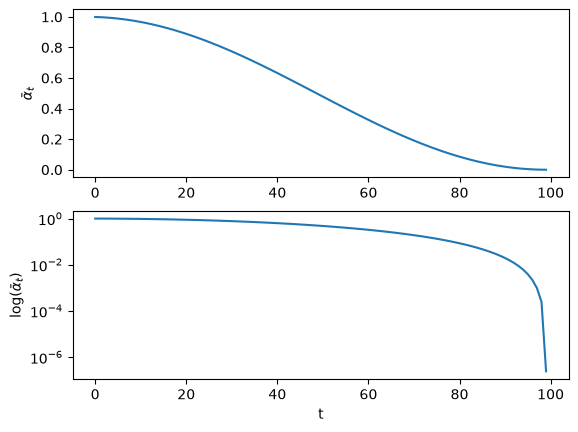

In [2]:
fig, axes = plt.subplots(2,1)
ax = axes[0]
ax.plot(alpha_bars)
ax.set_ylabel(r"$\bar{\alpha}_t$")

ax = axes[1]
ax.plot(alpha_bars)
ax.set_yscale("log")
ax.set_ylabel(r"log($\bar{\alpha}_t)$")
ax.set_xlabel("t")

In [3]:
# -----------------------
# noise prediction model
#
# eps_theta(x_k, k)
# -----------------------
class DiffusionModel(nn.Module):

    def __init__(self, hidden=64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.GELU(),

            nn.Linear(hidden, hidden),
            nn.GELU(),

            nn.Linear(hidden, 1),
        )

    def forward(self, x_k, k):

        k = (
            k.float()
            .view(-1, 1)
            / T
        )

        return self.net(
            torch.cat(
                [x_k, k],
                dim=1
            )
        )

model = DiffusionModel().to(device)

![fig/1515_forward_model.png](fig/1515_forward_model.png)

この関数は **forward diffusion**

$$
q(x_k|x_0)
$$

を実装しています。

数式

$$
x_k
=
\sqrt{\bar{\alpha}_k},x_0
+
\sqrt{1-\bar{\alpha}_k},\epsilon
$$



In [4]:
opt = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)


def q_sample(x0, k, eps):

    alpha_bar_k = (
        alpha_bars[k]
        .view(-1, 1)
    )

    x_k = (
        torch.sqrt(alpha_bar_k) * x0
        +
        torch.sqrt(
            1.0 - alpha_bar_k
        ) * eps
    )

    return x_k

In [5]:
# -----------------------
# training
# -----------------------
batch_size = 256
n_iter = 5000

losses = []

for step in range(n_iter):
    # -------------------
    # sample data x_0
    # -------------------
    x0 = sample_target(batch_size)

    # -------------------
    # sample timestep k
    # -------------------
    k = torch.randint(0, T, (batch_size,), device=device)

    # -------------------
    # Gaussian random
    # eps ~ N(0,I)
    # -------------------
    eps = torch.randn_like(x0)

    # -------------------
    # create noisy sample
    #
    # x_k
    # =
    # sqrt(alpha_bar_k)x_0
    # +
    # sqrt(1-alpha_bar_k)eps
    # -------------------
    x_k = q_sample(x0, k, eps)

    # -------------------
    # predict eps
    # -------------------
    eps_pred = model(x_k, k)

    loss = ((eps_pred - eps) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()

    losses.append(loss.item())

    if step % 500 == 0:
        print(step, loss.item())

0 0.9540845155715942
500 0.48348888754844666
1000 0.5316259264945984
1500 0.42675548791885376


2000 0.5924212336540222


2500 0.6117494106292725


3000 0.5925390720367432
3500 0.5260674357414246


4000 0.5379107594490051


4500 0.5560680627822876


![fig/1515_training.png](fig/1515_training.png)

### モデルと損失関数のまとめ

![fig/1517_loss.png](fig/1517_loss.png)



## Reverse diffusion

生成時には、forward process の終端であるガウスノイズ

$$
x_T\sim\mathcal N(0,I)
$$

から開始し、

$$
x_T\rightarrow x_{T-1}^{pred}\rightarrow\cdots\rightarrow x_0^{pred}
$$

の順にノイズを除去する。

各時刻 $k$ では、ニューラルネットワークが現在の状態 $x_k$ に含まれるノイズ

$$
\epsilon_\theta(x_k,k)
$$

を予測する。

(以下は天下りになります。）

この予測値を用いて、逆拡散分布

$$
p_\theta(x_{k-1}\mid x_k)
=
\mathcal N
\left(
x_{k-1};
\mu_\theta(x_k,k),
\tilde{\beta}_k I
\right)
$$

の平均を

$$
\mu_\theta(x_k,k)
=
\frac{1}{\sqrt{\alpha_k}}
\left[
x_k-
\frac{\beta_k}{\sqrt{1-\bar{\alpha}_k}}
\epsilon_\theta(x_k,k)
\right]
$$

として計算する。

分散には forward posterior の分散

$$
\tilde{\beta}_k
=
\beta_k
\frac{1-\bar{\alpha}_{k-1}}
{1-\bar{\alpha}_k}
$$

を用いる。したがって、各逆拡散ステップでは

$$
x_{k-1}
=
\mu_\theta(x_k,k)
+
\sqrt{\tilde{\beta}_k},z,
\qquad
z\sim\mathcal N(0,I)
$$

として $x_{k-1}$ をサンプリングする。

最後のステップでは、生成結果に新たなノイズを加えず、

$$
x_0=\mu_\theta(x_1,1)
$$

とする。

コードでは、`eps_pred` が予測ノイズ、`mean` が逆拡散分布の平均、`posterior_variance_k` が $\tilde{\beta}_k$ に対応する。この処理を時刻 $T$ から0まで繰り返すことで、ランダムノイズからデータ $x_0$ を生成する。


In [6]:
# -----------------------
# reverse diffusion
#
# x_T -> ... -> x_0
# -----------------------
@torch.no_grad()
def sample(model, n=10000):
    model.eval()

    # -------------------
    # start from noise
    #
    # x_T ~ N(0, I)
    # -------------------
    x = torch.randn(
        n,
        1,
        device=device,
    )

    for k in reversed(range(T)):
        k_batch = torch.full(
            (n,),
            k,
            device=device,
            dtype=torch.long,
        )

        beta_k = betas[k]
        alpha_k = alphas[k]
        alpha_bar_k = alpha_bars[k]

        # -------------------
        # predict noise
        #
        # eps_theta(x_k, k)
        # -------------------
        eps_pred = model(
            x,
            k_batch,
        )

        # -------------------
        # DDPM reverse mean
        #
        # mu_theta(x_k, k)
        # =
        # 1 / sqrt(alpha_k)
        # [
        #   x_k
        #   -
        #   beta_k
        #   / sqrt(1-alpha_bar_k)
        #   * eps_theta(x_k,k)
        # ]
        # -------------------
        mean = (
            1.0
            / torch.sqrt(alpha_k)
            * (
                x
                -
                beta_k
                / torch.sqrt(
                    1.0 - alpha_bar_k
                )
                * eps_pred
            )
        )

        # -------------------
        # sample x_{k-1}
        #
        # x_{k-1}
        # =
        # mean
        # +
        # sqrt(beta_tilde_k) z
        # -------------------
        if k > 0:
            z = torch.randn_like(x)

            posterior_variance_k = (
                posterior_variance[k]
            )

            x = (
                mean
                +
                torch.sqrt(
                    posterior_variance_k
                )
                * z
            )
        else:
            # 最後のステップではnoiseを加えない
            x = mean

    return (
        x.cpu()
        .numpy()
        .ravel()
    )

![fig/1517_generation.png](fig/1517_generation.png)


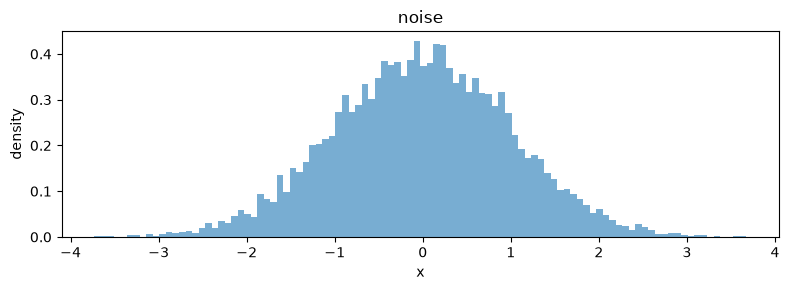

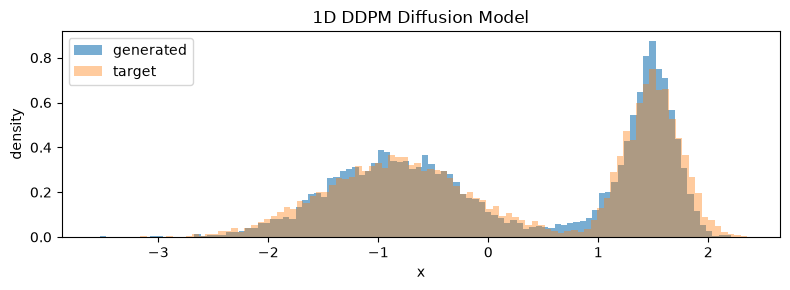

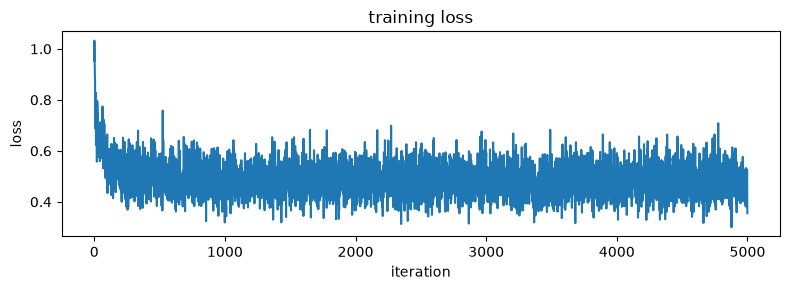

In [7]:
x_rand = torch.randn(
    10000,
    1)
plt.figure(figsize=(8, 3))
plt.hist(x_rand.numpy().ravel(), bins=100, density=True, alpha=0.6)
plt.ylabel("density")
plt.xlabel("x")
plt.title("noise")
plt.tight_layout()
plt.show()
# -----------------------
# generate samples
# -----------------------
x_gen = sample(model, n=10000)

# -----------------------
# plot
# -----------------------
plt.figure(figsize=(8, 3))
plt.hist(x_gen, bins=100, density=True, alpha=0.6, label="generated")
x_true = sample_target(10000).cpu().numpy().ravel()
plt.hist(x_true, bins=100, density=True, alpha=0.4, label="target")
plt.legend()
plt.xlabel("x")
plt.ylabel("density")
plt.title("1D DDPM Diffusion Model")
plt.tight_layout()
plt.show()

# -----------------------
# training loss
# -----------------------
plt.figure(figsize=(8, 3))
plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("loss")
plt.title("training loss")
plt.tight_layout()
plt.show()